## Homework 4

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [3]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [4]:
!wget $data -O data_homework_4.csv 

--2026-10-18 07:41:09--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolvendo raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8001::154, 2606:50c0:8003::154, 2606:50c0:8000::154, ...
Conectando-se a raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8001::154|:443... conectado.
A requisição HTTP foi enviada, aguardando resposta... 200 OK
Tamanho: 278746 (272K) [text/plain]
Salvando em: ‘data_homework_4.csv’

data_homework_4.csv 100%[===================>] 272,21K  --.-KB/s    em 0,05s   

2026-10-18 07:41:09 (5,82 MB/s) - ‘data_homework_4.csv’ salvo [278746/278746]



In [5]:
df = pd.read_csv('data_homework_4.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


### Data preparation

* Check if the missing values are presented in the features.
* If there are missing values:
    * For categorical features, replace them with 'NA'
    * For numerical features, replace with with 0.0 


Split the data into 3 parts with these exact calls:

```python
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
```

In [6]:
df.dtypes

lead_source                  object
industry                     object
employment_status            object
location                     object
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [7]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [8]:
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
df[numerical] = df[numerical].fillna(0)
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income                 0
number_of_courses_viewed      0
interaction_count             0
lead_score                    0
converted                     0
dtype: int64

In [9]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
df[categorical] = df[categorical].fillna('NA')
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [10]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [11]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [12]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [13]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

### Question 1: ROC AUC feature importance

ROC AUC could also be used to evaluate feature importance of numerical variables. 

Let's do that

* For each numerical variable, use it as score (aka prediction) and compute the AUC with the `y` variable as ground truth.
* Use the training dataset for that


If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. `-df_train['balance']`)

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`

In [14]:
from sklearn.metrics import roc_auc_score

In [15]:
auc_lead_score = roc_auc_score(y_train, df_train.lead_score)
print(f'{auc_lead_score:.3f} :auc of lead_score')

auc_number_of_courses_viewed = roc_auc_score(y_train, df_train.number_of_courses_viewed)
print(f'{auc_number_of_courses_viewed:.3f} :auc of number_of_courses_viewed')

auc_interaction_count = roc_auc_score(y_train, df_train.interaction_count)
print(f'{auc_interaction_count:.3f} :auc of interaction_count')

auc_annual_income = roc_auc_score(y_train, df_train.annual_income)
print(f'{auc_annual_income:.3f} :auc of annual_income')

0.788 :auc of lead_score
0.723 :auc of number_of_courses_viewed
0.765 :auc of interaction_count
0.608 :auc of annual_income


### lead_score is the higher auc roc number.

### Question 2: Training the model

Apply one-hot-encoding using `DictVectorizer` and train the logistic regression with these parameters:

```python
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
```

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732
- 0.832


In [16]:
train_dicts = df_train[categorical + numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)

X_train[0]

array([8.0198e+04, 0.0000e+00, 1.0000e+00, 0.0000e+00, 0.0000e+00,
       0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
       0.0000e+00, 0.0000e+00, 1.0000e+00, 9.0000e+00, 9.1000e-01,
       0.0000e+00, 0.0000e+00, 0.0000e+00, 1.0000e+00, 0.0000e+00,
       0.0000e+00, 0.0000e+00, 0.0000e+00, 1.0000e+00, 0.0000e+00,
       0.0000e+00, 0.0000e+00, 5.0000e+00])

In [17]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

print(model.intercept_[0].round(3), '\n')
print(model.coef_[0].round(3))

-0.093 

[-0.    -0.001  0.033 -0.023 -0.055 -0.047 -0.004 -0.025 -0.012 -0.024
 -0.009 -0.032  0.012  0.252  0.019 -0.002 -0.041  0.013 -0.065  0.027
 -0.025 -0.005 -0.02  -0.015 -0.01  -0.022 -0.021  0.105]


In [18]:
val_dicts = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dicts)
y_pred = model.predict_proba(X_val)[:, 1]

In [19]:
roc_auc_score_val = roc_auc_score(y_val, y_pred)
print(f'roc auc score = {roc_auc_score_val:.3f}')

roc auc score = 0.732


### Question 3: Precision and Recall

Now let's compute precision and recall for our model.

* Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
* For each threshold, compute precision and recall
* Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at
which both metrics are zero, and choose the threshold with the smallest
absolute difference between precision and recall.

* 0.43
* 0.63
* 0.73
* 0.83

In [20]:
def precision_recall_dataframe(y_val, y_pred):
    scores = []
    diff = 1.0

    thresholds = np.linspace(0, 1, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)

        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()
        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()
        
        if (tp + fp) > 0: precision = tp / (tp + fp)
        if (tp + fn) > 0: recall = tp / (tp + fn)
        aux = abs(precision - recall)
        if aux < diff:
            tmin = t
            diff = aux   
        scores.append((t, precision, recall))
        
    columns = ['threshold', 'precision', 'recall']
    df_precision_recall = pd.DataFrame(scores, columns=columns)

    return [tmin, diff], df_precision_recall

In [21]:
diff, df_precision_recall = precision_recall_dataframe(y_val, y_pred)
df_precision_recall[::10]

,threshold,precision,recall
0,0.0,0.586000,1.000000
10,0.1,0.586000,1.000000
20,0.2,0.586000,1.000000
30,0.3,0.592518,1.000000
40,0.4,0.612834,0.977816
50,0.5,0.643636,0.906143
60,0.6,0.706337,0.779863
70,0.7,0.791349,0.530717
80,0.8,0.858025,0.237201
90,0.9,0.950000,0.032423


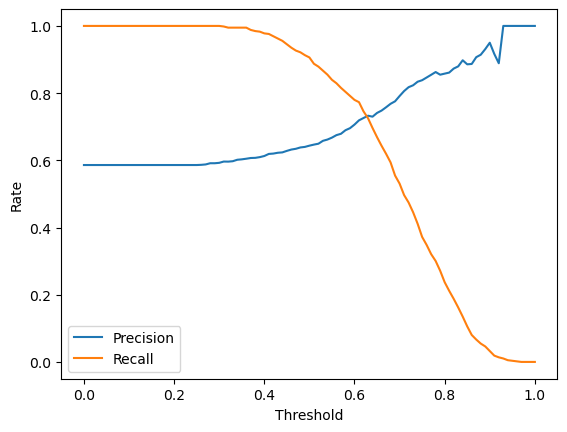

In [22]:
plt.plot(df_precision_recall.threshold.values, df_precision_recall.precision.values, label = "Precision")
plt.xlabel("Threshold")
plt.ylabel("Rate")

plt.plot(df_precision_recall.threshold.values, df_precision_recall.recall.values, label="Recall")
plt.legend()
plt.show()

In [23]:
print(f'In threshold = {diff[0]}, the smallest absolute difference between precision and recall is {round(diff[1], 5)}.')

In threshold = 0.63, the smallest absolute difference between precision and recall is 0.0075.


### Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41
- 0.61
- 0.81

In [24]:
df_precision_recall['F1'] = 2 * (df_precision_recall.precision * df_precision_recall.recall) / (df_precision_recall.precision + df_precision_recall.recall)

In [25]:
df_precision_recall[35:45]

,threshold,precision,recall,F1
35,0.35,0.602896,0.994881,0.750805
36,0.36,0.604772,0.994881,0.752258
37,0.37,0.606918,0.988055,0.751948
38,0.38,0.607368,0.984642,0.751302
39,0.39,0.609524,0.982935,0.752449
40,0.40,0.612834,0.977816,0.753452
41,0.41,0.619048,0.976109,0.757616
42,0.42,0.620087,0.969283,0.756325
43,0.43,0.622517,0.962457,0.756032
44,0.44,0.623608,0.955631,0.754717


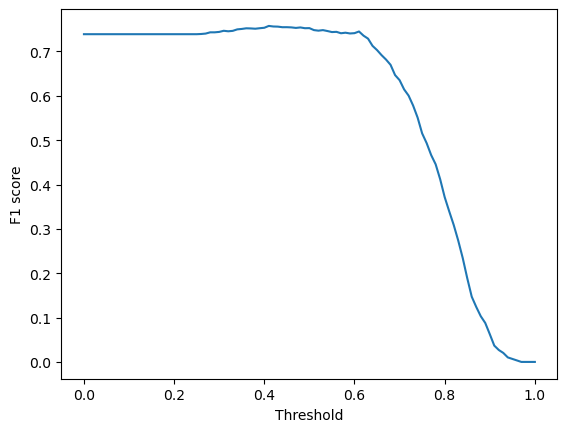

In [26]:
plt.plot(df_precision_recall.threshold.values, df_precision_recall.F1.values, label = "F1 score")
plt.xlabel("Threshold")
plt.ylabel("F1 score")
plt.show()

In [27]:
idx = df_precision_recall['F1'].idxmax()

In [28]:
print(f'In threshold = {df_precision_recall.threshold[idx]:.2f}, the greatest F1 score is {df_precision_recall.F1[idx]:.5f}.')

In threshold = 0.41, the greatest F1 score is 0.75762.


### Question 5: 5-Fold CV


Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

```
KFold(n_splits=5, shuffle=True, random_state=1)
```

* Iterate over different folds of `df_full_train`
* Split the data into train and validation
* Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
* Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

- 0.001
- 0.007
- 0.013
- 0.060

In [29]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [30]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [31]:
from sklearn.model_selection import KFold

In [32]:

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train, C=1.0)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print('The mean auc is %.3f +- %.3f' % (np.mean(scores), np.std(scores)))

The mean auc is 0.732 +- 0.007


### Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter `C`

* Iterate over the following `C` values: `[0.000001, 0.001, 1]`
* Initialize `KFold` with the same parameters as previously
* Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
* Compute the mean ROC AUC as well as the std (round the mean and std to 3
  decimal digits).

Which `C` leads to the best mean ROC AUC?

- 0.000001
- 0.001
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest `C`.

In [33]:
!pip install tqdm

In [34]:
from tqdm.auto import tqdm

In [35]:
n_splits = 5

for C in tqdm([0.000001, 0.001, 1]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007


In [36]:
print(f'C = {0.001} leads to the best mean ROC AUC = {0.749}')

C = 0.001 leads to the best mean ROC AUC = 0.749
